In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split

In [3]:
# with header (default)
data = pd.read_csv("data1.csv")

# without header
data1 = pd.read_csv("data1.csv", header=None)

print(data.head(2))
print(data1.head(2))

   Year              Datetime    Stage         Stadium         City  \
0  1930  13 Jul 1930 - 15:00   Group 1         Pocitos  Montevideo    
1  1930  13 Jul 1930 - 15:00   Group 4  Parque Central  Montevideo    

  Home Team Name  Home Team Goals  Away Team Goals Away Team Name  \
0         France                4                1         Mexico   
1            USA                3                0        Belgium   

  Win conditions  Attendance  Half-time Home Goals  Half-time Away Goals  \
0                     4444.0                     3                     0   
1                    18346.0                     2                     0   

                  Referee               Assistant 1            Assistant 2  \
0  LOMBARDI Domingo (URU)     CRISTOPHE Henry (BEL)    REGO Gilberto (BRA)   
1       MACIAS Jose (ARG)  MATEUCCI Francisco (URU)  WARNKEN Alberto (CHI)   

   RoundID  MatchID Home Team Initials Away Team Initials  
0      201     1096                FRA                

In [4]:
print(data.head()) # first 5 rows
print(data.tail()) # last 5 rows
print(data.shape) # gives [rows, columns]
print(data.describe()) # gives statistics
print(data.info()) # columns, non null, datatypes
print(data.dtypes) # datatypes
print(data.index) # row indexes

   Year              Datetime    Stage         Stadium         City  \
0  1930  13 Jul 1930 - 15:00   Group 1         Pocitos  Montevideo    
1  1930  13 Jul 1930 - 15:00   Group 4  Parque Central  Montevideo    
2  1930  14 Jul 1930 - 12:45   Group 2  Parque Central  Montevideo    
3  1930  14 Jul 1930 - 14:50   Group 3         Pocitos  Montevideo    
4  1930  15 Jul 1930 - 16:00   Group 1  Parque Central  Montevideo    

  Home Team Name  Home Team Goals  Away Team Goals Away Team Name  \
0         France                4                1         Mexico   
1            USA                3                0        Belgium   
2     Yugoslavia                2                1         Brazil   
3        Romania                3                1           Peru   
4      Argentina                1                0         France   

  Win conditions  Attendance  Half-time Home Goals  Half-time Away Goals  \
0                     4444.0                     3                     0   
1     

In [25]:
# idhar bas independent and dependent variables banake rakha hai (x and y)

# idhar hum ye wala method use kar rahe hai kyuki yehi suitable hai, iloc wale ke lie contiguous lagta hai islie wo nai kia
inputfeatures=['Home Team Goals','Away Team Goals','Attendance','Half-time Home Goals','Half-time Away Goals']
x=data[inputfeatures]

# ye ek if else condition hai; agar home team jiti toh true return hoga jo 'astype(int)' se 1 me convert hojaega
data['result'] = (data['Home Team Goals'] > data['Away Team Goals']).astype(int)
y=data['result']

print(x.head())
print(y.head())

   Home Team Goals  Away Team Goals  Attendance  Half-time Home Goals  \
0                4                1      4444.0                     3   
1                3                0     18346.0                     2   
2                2                1     24059.0                     2   
3                3                1      2549.0                     1   
4                1                0     23409.0                     0   

   Half-time Away Goals  
0                     0  
1                     0  
2                     0  
3                     0  
4                     0  
0    1
1    1
2    1
3    1
4    1
Name: result, dtype: int64


In [15]:
# missing values handle karo

missing = data.isnull().sum()
print("missing values initially:\n",missing)

missing values initially:
 Year                    0
Datetime                0
Stage                   0
Stadium                 0
City                    0
Home Team Name          0
Home Team Goals         0
Away Team Goals         0
Away Team Name          0
Win conditions          0
Attendance              2
Half-time Home Goals    0
Half-time Away Goals    0
Referee                 0
Assistant 1             0
Assistant 2             0
RoundID                 0
MatchID                 0
Home Team Initials      0
Away Team Initials      0
Result                  0
result                  0
dtype: int64


In [26]:
# as we can see, attendance column me 2 missing nikla hai, so handle that.

data['Attendance'].fillna(data['Attendance'].mean(), inplace=True) # inplace line ensures that changes are made in original file only and not a separate copy
print("missing values now:\n", data.isnull().sum())

missing values now:
 Year                    0
Datetime                0
Stage                   0
Stadium                 0
City                    0
Home Team Name          0
Home Team Goals         0
Away Team Goals         0
Away Team Name          0
Win conditions          0
Attendance              0
Half-time Home Goals    0
Half-time Away Goals    0
Referee                 0
Assistant 1             0
Assistant 2             0
RoundID                 0
MatchID                 0
Home Team Initials      0
Away Team Initials      0
Result                  0
result                  0
dtype: int64


In [31]:
# abhi hum categorical data handle kar rhe hai. after observing dataset, only 'stage' column was found useful islie bas wahi convert karrhe

le = LabelEncoder()    # storing this function in a variable
data['Stage_new'] = le.fit_transform(data['Stage'])    # 'fit' finds unique names, 'transform' replaces them with numbers, this is stored in new column 'stage_new'
print(data[['Stage','Stage_new']].head())

     Stage  Stage_new
0  Group 1          2
1  Group 4          5
2  Group 2          3
3  Group 3          4
4  Group 1          2


In [34]:
# split karrhe dataset ko

x_final = data[['Home Team Goals', 'Away Team Goals', 'Attendance',
                 'Half-time Home Goals', 'Half-time Away Goals', 'Stage_new']]    
# x ka naya variable banaya kyuki ab 'stage_new' bhi include hoga
# y same rahega

x_train, x_test, y_train, y_test = train_test_split (
    x_final, y, train_size=0.8, random_state=1
)

print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(681, 6) (681,) (171, 6) (171,)


In [38]:
# scale karrrhe values ko

scaler = MinMaxScaler(feature_range = (0,1))    # 'scaler' variable banaya aur usme scale range define kiya
x_train_new = scaler.fit_transform(x_train)   # 'x_train_new' variable banaya aur usme scaled values store ki  ('fit' means 'identify', 'transform' means 'apply changes')
x_test_new = scaler.transform(x_test)     # not using 'fit' here because model might accidently see test data which would result in artifical results and data leakage
print(x_train_new[:5])
print(x_test_new[:5])

[[0.1        0.         0.61793424 0.16666667 0.         0.09090909]
 [0.         0.28571429 0.36659878 0.         0.2        0.63636364]
 [0.6        0.42857143 0.17738144 0.5        0.2        0.72727273]
 [0.1        0.         0.37161478 0.         0.         0.63636364]
 [0.1        0.14285714 0.07764329 0.16666667 0.2        0.18181818]]
[[0.1        0.42857143 0.21006692 0.16666667 0.2        0.68181818]
 [0.1        0.28571429 0.21588595 0.         0.2        0.68181818]
 [0.2        0.         0.17530986 0.         0.         0.13636364]
 [0.         0.57142857 0.22101833 0.         0.2        0.36363636]
 [0.1        0.14285714 0.29406459 0.         0.         0.54545455]]


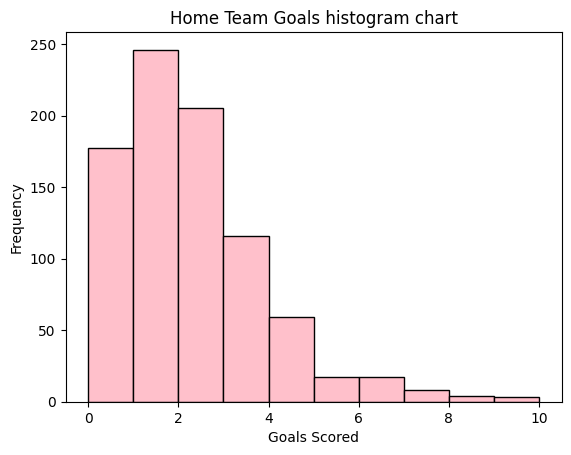

In [77]:
# histogram me automatically 'frequency' ke against plot hota hai isliye idhar bas column bata rhe
# histogram useful for numerical data and it is continuous

plt.hist(data['Home Team Goals'], bins=10, color='pink', edgecolor='black') # column = Home Team Goals, bins matlab kitna rectangle chahie
plt.title('Home Team Goals histogram chart') 
plt.xlabel('Goals Scored')
plt.ylabel('Frequency')
plt.show()

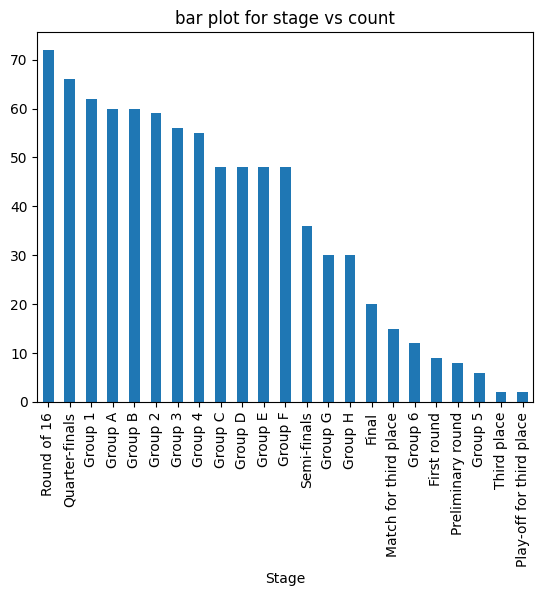

In [79]:
# bar plot is useful for categorical data and it is non-continuous
# islie idhar hum stage column lenge

data['Stage'].value_counts().plot(kind = 'bar')
plt.title('bar plot for stage vs count')
plt.show()

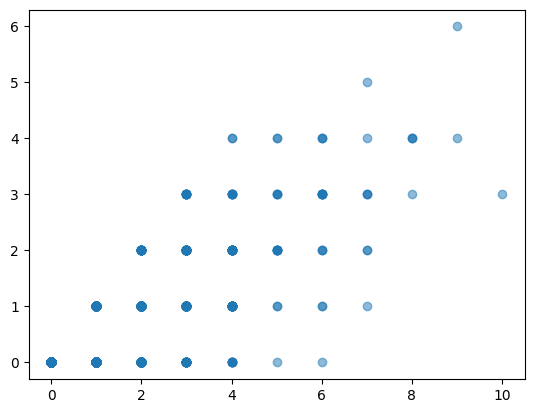

In [91]:
# scatter plot shows correlation, and we can make some things out by observing some patterns [refer notes] 
plt.scatter(data['Home Team Goals'], data['Half-time Home Goals'], alpha=0.5)
plt.show()

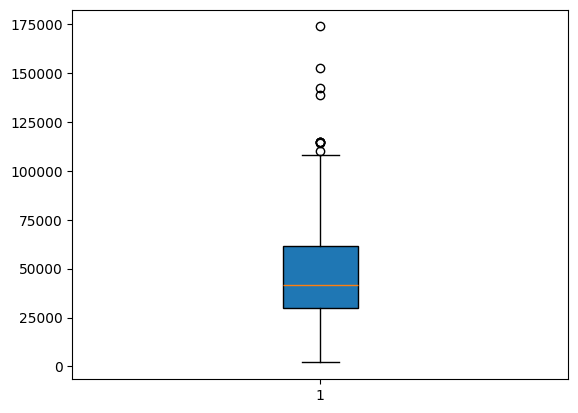

In [103]:
plt.boxplot(data['Attendance'],patch_artist=True)
plt.show()